In [23]:
from math import nan
import sklearn as sk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [37]:
LD = pd.read_csv("OriginalDatasets/Leescatalogus_Recommender_Definitief_leesmateriaal_Jarno.csv")
LD = LD.drop_duplicates()
LD

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,boek,3F,WOII;onderduik,LM-0001,fictie,WOII,WOII; onderduik,...,verhalen,Educatief Media,2025,PDF,CAT-00001,B1,Hoog,NaN,fictie,3.4
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,Boek,3F,spanning;stalking,LM-0002,fictie,spanning,spanning; stalking,...,verhalen,Leeswereld,2005,Digitaal,CAT-00002,B2,hoog,NT2,fictie,2.5
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",Boek,2F,liefde;relaties,LM-0003,fictie,liefde,liefde; relaties,...,verhalen,Nbd/Biblion,2025,Digitaal,CAT-00003,B2,Midden,NT2,fictie,3.8
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,Boek,3F,ontmoeting;verbondenheid,LM-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,Uitgeverij Noord,2018,Digitaal,CAT-00004,batch-2,Laag,NT2,fictie,3.9
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,Boek,2F,geheimen;schuld,LM-0005,fictie,geheimen,geheimen; schuld,...,verhalen,Uitgeverij Noord,2011,online,CAT-00005,B3,Laag,MBO/NT2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,Zorgen om studiefinanciering: 'aanpak nodig',Lars Dekker (NOS),"criminaliteit, klimaat, media",blogpost,3F,https://www.autoriteitpersoonsgegevens.nl/arti...,LM-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,Online,CAT-00279,B2,Midden,MBO,informatief,NaN
279,Wat betekent jeugdcriminaliteit voor jou?,Daan de Vries (NOS),"werk, AI, privacy, jongeren",online artikel,3F,https://www.kijkmagazine.nl/artikel/wat-beteke...,LM-0280,informatief,NaN,NaN,...,verhalen,Educatief Media,NaN,Online,CAT-00280,B2,Hoog,NaN,informatief,NaN
280,Zolang het belofte duurt,Vera Prins,Een man van veertig wordt geconfronteerd met d...,Boek - roman,2F,NaN,LM-0281,fictie,NaN,NaN,...,verhalen,NaN,2005,PDF,CAT-00281,B2,Hoog,MBO/NT2,fictie,NaN
281,Zomer zonder grens,Jelle Meijer,"Toegankelijk verhaal over onderzoek, burgersch...",Boek - thriller,2F,onderzoek;burgerschap,LM-0282,NaN,onderzoek,onderzoek; burgerschap,...,verhalen,Leeswereld,1998,Papier,CAT-00282,batch-2,Midden,NaN,NaN,NaN


In [25]:
LD["gegevensstatus"].unique()

<StringArray>
['Aangevuld (deels gesimuleerd)', 'gecontroleerd', 'In behandeling', nan]
Length: 4, dtype: str

In [7]:
LD["Type materiaal"].unique()

<StringArray>
[           'boek',            'Boek',     'tijdschrift',  'krant (papier)',
  'digitale krant', 'Boek - thriller',    'Boek - roman',               nan,
  'online artikel',     'dichtbundel',        'blogpost']
Length: 11, dtype: str

In [13]:
LD["Type materiaal"] = LD["Type materiaal"].replace(
    r"^[Bb]oek\s?-?\s?.*?$", "boek", regex=True
)
LD["Type materiaal"].unique()

<StringArray>
[          'boek',    'tijdschrift', 'krant (papier)', 'digitale krant',
              nan, 'online artikel',    'dichtbundel',       'blogpost']
Length: 8, dtype: str

<function matplotlib.pyplot.show(close=None, block=None)>

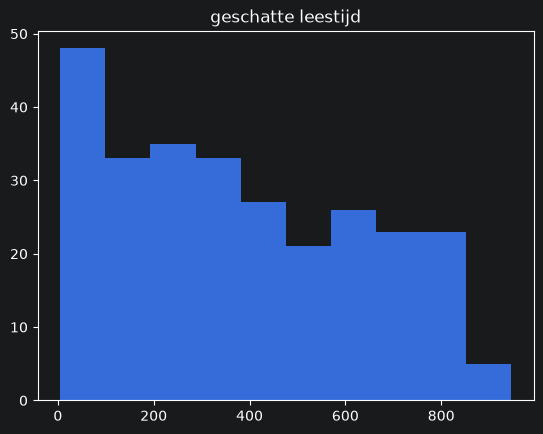

In [24]:
plt.title("geschatte leestijd")
plt.hist(LD["geschatte_leestijd_min"])
plt.show

In [21]:
# Geschatte leestijd invullen
imp_frequent = sk.impute.SimpleImputer(missing_values=nan, strategy="average")
imp_frequent.fit(LD)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](32,)","['Titel','Auteur','Korte omschrijving',...,'doelgroep_extra','genre_kopie', 'Gemiddelde beoordeling']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,32
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[object](32,)","['Wat is een rechtsstaat?','Autoriteit Persoonsgegevens', 'Onderwijs, burgerschap, AI',...,'MBO','fictie',3.4]"


In [19]:
LD[(LD["genre"].isnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
7,De man van de bloemen,Johan van Caeneghem,Ontroerend verhaal over een onverwachte ontmoe...,boek,2F,ontmoeting;hoop,LM-0008,NaN,ontmoeting,ontmoeting; hoop,...,verhalen,NaN,1998,Papier,CAT-00008,B2,Laag,MBO/NT2,NaN,3.6
12,Een echte man,Yvonne Kroonenberg,Met humor onderzoekt dit boek verwachtingen ro...,boek,2F,identiteit;relaties,LM-0013,NaN,identiteit,identiteit; relaties,...,verhalen,Uitgeverij Noord,NaN,NaN,CAT-00013,B3,NaN,NT2,NaN,3.5
14,Floortje Dessing reisverhalen,Floortje Dessing,Verzameling reisverhalen waarin bijzondere bes...,boek,2F,reizen;cultuur,LM-0015,NaN,reizen,reizen; cultuur,...,vrije tijd,NaN,2013,online,CAT-00015,B2,Laag,MBO,NaN,3.7
30,Sherlock Holmes wereldverhalen,Arthur Conan Doyle,Bundel klassieke detectiveverhalen waarin Sher...,boek,3F,mysterie;detective,LM-0031,NaN,mysterie,mysterie; detective,...,verhalen,Leeswereld,NaN,online,CAT-00031,B2,hoog,NaN,NaN,3.6
53,Dode meisjes praten niet,Sandra J. Paul,Thriller waarin een ogenschijnlijk afgesloten ...,boek,2F,thriller;mysterie,LM-0054,NaN,thriller,thriller; mysterie,...,verhalen,Leeswereld,1998,Papier,CAT-00054,batch-2,Midden,NaN,NaN,3.6
67,Het geluid van de stilte,Inez Weski,"Persoonlijk relaas over rechtspraak, media-aan...",NaN,3F+,NaN,LM-0068,NaN,NaN,NaN,...,verhalen,Leeswereld,NaN,Papier,CAT-00068,B3,Midden,MBO,NaN,2.8
72,De strafzaak tegen Willem Holleeder,Frank Wieland,Reconstructie van een van de bekendste Nederla...,boek,3F,NaN,LM-0073,NaN,NaN,NaN,...,verhalen,Uitgeverij Noord,1998,Papier,CAT-00073,NaN,Laag,MBO/NT2,NaN,2.6
77,Latino King,Bibi Dumon Tak,Waargebeurd verhaal dat inzicht geeft in jeugd...,boek,2F,NaN,LM-0078,NaN,NaN,NaN,...,verhalen,Leeswereld,NaN,Digitaal,CAT-00078,B1,NaN,NaN,NaN,3.1
82,Het blauw van de oceaan,Zoulfa Katouh,"Actuele roman over identiteit, discriminatie e...",boek,3F,NaN,LM-0083,NaN,NaN,NaN,...,verhalen,NaN,NaN,NaN,CAT-00083,B2,Laag,MBO,NaN,3.4
96,Confrontaties,Simone Atangana Bekono,"Indringende roman over identiteit, woede en ze...",boek,3F+,NaN,LM-0097,NaN,NaN,NaN,...,verhalen,NaN,1998,online,CAT-00097,B2,Hoog,NaN,NaN,2.7


In [16]:
ldExtract = LD[(LD["Niveau"].isnull())]
ldExtract

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
37,Libello voor mannen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,LM-0038,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,papier,CAT-00038,NaN,hoog,NaN,fictie,2.9
38,Libello voor vrouwen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,LM-0039,fictie,NaN,NaN,...,verhalen,Uitgeverij Noord,2013,Papier,CAT-00039,batch-2,Laag,NT2,fictie,3.5
39,De Startkrant,NaN,Eenvoudig geschreven krant met actueel nieuws ...,krant (papier),NaN,NaN,LM-0040,fictie,NaN,NaN,...,verhalen,Leeswereld,2099,Papier,CAT-00040,batch-2,NaN,NaN,fictie,3.3
40,De Startweekkrant,NaN,Wekelijkse digitale krant met begrijpelijke ar...,digitale krant,NaN,NaN,LM-0041,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,Digitaal,CAT-00041,NaN,Midden,NT2,fictie,3.1
156,"Tekorten zorgpersoneel nemen sneller toe, 'hoo...",NOS,"Zorg, arbeidsmarkt",online artikel,NaN,https://nos.nl/artikel/2548636-tekorten-zorgpe...,LM-0157,informatief,NaN,NaN,...,verhalen,NaN,2013,PDF,CAT-00157,B3,Hoog,NaN,informatief,3.5
157,Nieuwe generatie fysiotherapeuten valt uit na ...,Sander Zurhake (NOS),"Fysiotherapie, zorg",online artikel,NaN,https://nos.nl/artikel/2476626-nieuwe-generati...,LM-0158,informatief,NaN,NaN,...,verhalen,Leeswereld,2023,online,CAT-00158,batch-2,Midden,NT2,informatief,3.5
